# Graph-Based Empathic Environment - Testing & Exploration

This notebook validates and explores the new graph-based multi-agent environment.

## Key Features
- Agents are fixed nodes in a social graph (no movement)
- Graph edges determine who can see whose emotions
- Shared resource pool instead of spatial resources
- Actions: wait (0) or consume (1)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict

# Import graph-based modules
from social_graph import SocialGraph
from resource_pool import ResourcePool
from agent_graph import GraphDQNAgent, Agent, EmpathicRewardCalculator
from env_graph import EmpathicGraphEnv
from config import *

print("All imports successful!")

All imports successful!


## 1. Test SocialGraph Class

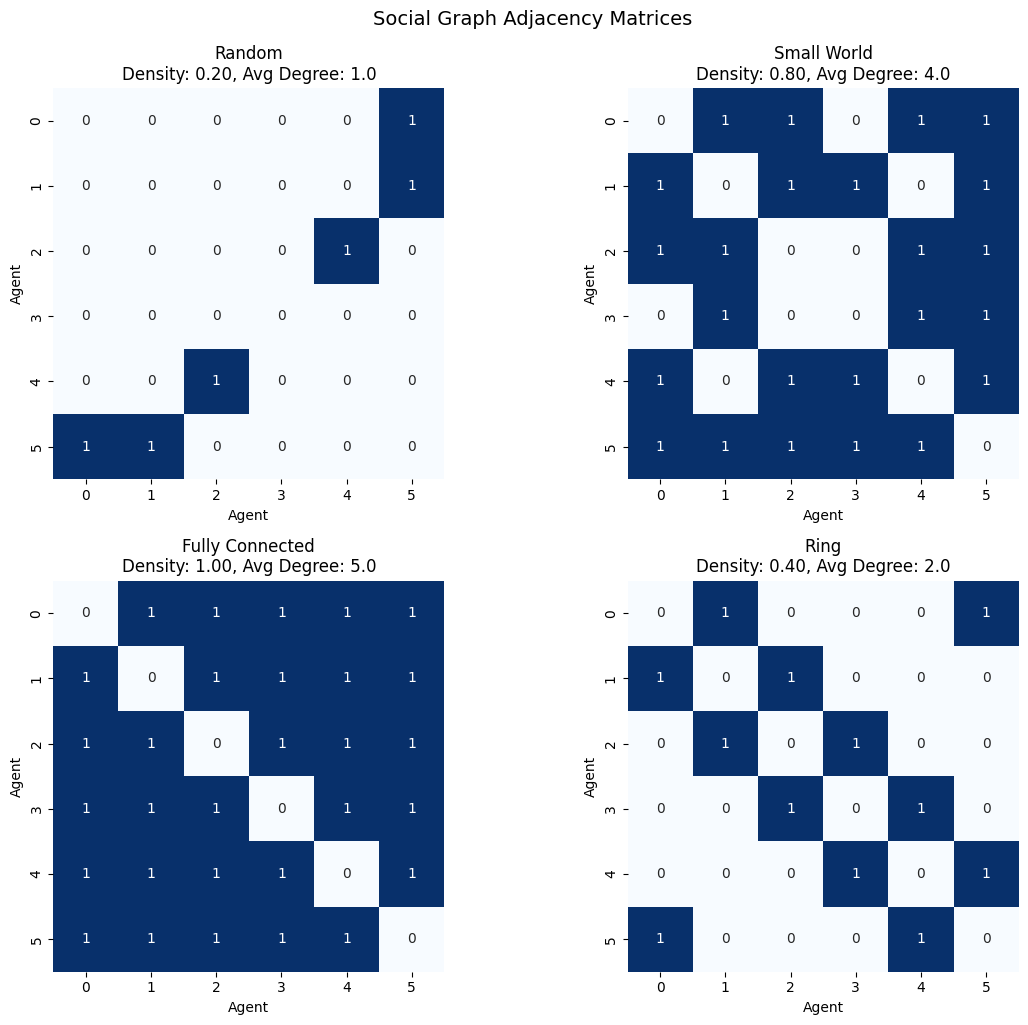

In [2]:
# Test different graph types
graph_types = ['random', 'small_world', 'fully_connected', 'ring']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, graph_type in enumerate(graph_types):
    graph = SocialGraph(
        num_agents=6,
        graph_type=graph_type,
        edge_probability=0.4,
        k=2,
        p=0.3,
        seed=42
    )
    
    ax = axes[idx]
    sns.heatmap(graph.adjacency, annot=True, cmap='Blues', ax=ax, 
                cbar=False, square=True, fmt='.0f')
    ax.set_title(f'{graph_type.replace("_", " ").title()}\nDensity: {graph.get_density():.2f}, Avg Degree: {graph.get_average_degree():.1f}')
    ax.set_xlabel('Agent')
    ax.set_ylabel('Agent')

plt.tight_layout()
plt.suptitle('Social Graph Adjacency Matrices', y=1.02, fontsize=14)
plt.show()

In [3]:
# Test neighbor queries
graph = SocialGraph(num_agents=5, graph_type='random', edge_probability=0.5, seed=42)

print(f"Graph: {graph}")
print(f"\nAdjacency Matrix:")
print(graph.adjacency)

print(f"\nNeighbors per agent:")
for i in range(5):
    neighbors = graph.get_neighbors(i)
    weights = graph.get_neighbor_weights(i)
    print(f"  Agent {i}: neighbors={neighbors}, weights={weights}")

Graph: SocialGraph(num_agents=5, density=0.40, avg_degree=1.6)

Adjacency Matrix:
[[0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0.]
 [1. 1. 0. 0. 1.]
 [0. 0. 0. 0. 1.]
 [0. 0. 1. 1. 0.]]

Neighbors per agent:
  Agent 0: neighbors=[2], weights={2: 1.0}
  Agent 1: neighbors=[2], weights={2: 1.0}
  Agent 2: neighbors=[0, 1, 4], weights={0: 1.0, 1: 1.0, 4: 1.0}
  Agent 3: neighbors=[4], weights={4: 1.0}
  Agent 4: neighbors=[2, 3], weights={2: 1.0, 3: 1.0}


## 2. Test ResourcePool Class

Initial: ResourcePool(current=50/100, mode=constant)
Normalized level: 0.50


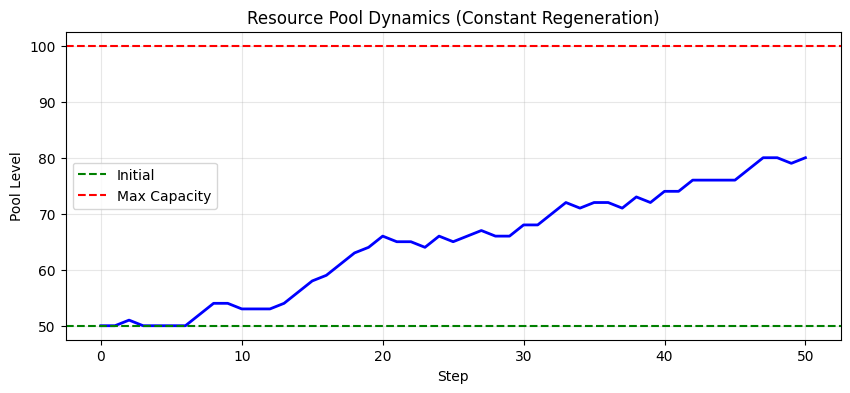


Final stats: {'current': 80, 'normalized_level': 0.8, 'total_consumed': 70, 'total_regenerated': 100.0, 'max_capacity': 100, 'is_empty': False}


In [4]:
# Test resource pool mechanics
pool = ResourcePool(
    initial_amount=50,
    max_capacity=100,
    regeneration_rate=2.0,
    regeneration_mode='constant'
)

print(f"Initial: {pool}")
print(f"Normalized level: {pool.get_normalized_level():.2f}")

# Simulate consumption and regeneration
levels = [pool.get_level()]
for step in range(50):
    # Random consumption (0-3 agents consume)
    num_consumers = np.random.randint(0, 4)
    if num_consumers > 0:
        served, indices = pool.consume_multiple(num_consumers)
    pool.regenerate()
    levels.append(pool.get_level())

plt.figure(figsize=(10, 4))
plt.plot(levels, 'b-', linewidth=2)
plt.axhline(y=50, color='g', linestyle='--', label='Initial')
plt.axhline(y=100, color='r', linestyle='--', label='Max Capacity')
plt.xlabel('Step')
plt.ylabel('Pool Level')
plt.title('Resource Pool Dynamics (Constant Regeneration)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"\nFinal stats: {pool.get_stats()}")

In [5]:
# Test simultaneous consumption with scarcity
pool = ResourcePool(initial_amount=3, max_capacity=10, regeneration_rate=0, regeneration_mode='none')

print("Testing scarce pool with 5 consumers wanting 1 each:")
print(f"Pool before: {pool.get_level()}")

served, indices = pool.consume_multiple(num_consumers=5, amount_per_consumer=1)
print(f"Served: {served} agents")
print(f"Indices served: {indices}")
print(f"Pool after: {pool.get_level()}")

Testing scarce pool with 5 consumers wanting 1 each:
Pool before: 3
Served: 3 agents
Indices served: [0, 1, 2]
Pool after: 0


## 3. Test EmpathicGraphEnv Environment

In [6]:
# Create environment
env = EmpathicGraphEnv(
    num_agents=5,
    max_neighbors=8,
    initial_pool=30,
    max_pool_capacity=50,
    regeneration_rate=1.0,
    regeneration_mode='constant',
    graph_type='random',
    edge_probability=0.5,
    empathy_alpha=0.5,
    max_steps=100
)

print(f"Observation space: {env.observation_space}")
print(f"Action space: {env.action_space}")

Observation space: Box(-1.0, 2.0, (19,), float32)
Action space: Discrete(2)


In [7]:
# Create agents
agents = [
    GraphDQNAgent(
        agent_id=i,
        observation_dim=OBSERVATION_DIM,
        action_size=2,
        epsilon=0.5  # Some exploration
    )
    for i in range(5)
]

env.set_agents(agents)
print(f"Created {len(agents)} agents")

GraphDQNAgent using device: cpu
Created 5 agents


In [8]:
# Run a single episode and collect data
obs, info = env.reset(seed=42)

print(f"Initial observation shape: {obs[0].shape}")
print(f"Initial info: {info}")
print(f"\nGraph adjacency:")
print(env.graph.adjacency)

Initial observation shape: (19,)
Initial info: {'steps': 0, 'pool_level': 30, 'graph_density': np.float64(0.4), 'graph_avg_degree': np.float64(1.6)}

Graph adjacency:
[[0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0.]
 [1. 1. 0. 0. 1.]
 [0. 0. 0. 0. 1.]
 [0. 0. 1. 1. 0.]]


In [9]:
# Run episode and track metrics
obs, _ = env.reset(seed=42)
for agent, o in zip(agents, obs):
    agent.reset(observation=o)

episode_data = {
    'pool_levels': [],
    'rewards': [[] for _ in range(5)],
    'consumptions': [0] * 5,
    'satisfactions': [[] for _ in range(5)],
    'actions': []
}

for step in range(100):
    # Record pre-step data
    episode_data['pool_levels'].append(env.pool.get_level())
    for i in range(5):
        episode_data['satisfactions'][i].append(agents[i].get_satisfaction())
    
    # Select actions
    actions = [agent.select_action(obs[i], training=True) for i, agent in enumerate(agents)]
    episode_data['actions'].append(actions.copy())
    
    # Step
    next_obs, rewards, terminated, truncated, info = env.step(actions)
    
    # Record post-step data
    for i in range(5):
        episode_data['rewards'][i].append(rewards[i])
        if info['consumed'][i]:
            episode_data['consumptions'][i] += 1
    
    # Update agents
    for i, agent in enumerate(agents):
        agent.step(next_obs[i], rewards[i], terminated or truncated)
    
    obs = next_obs
    if terminated or truncated:
        break

print(f"Episode finished at step {step + 1}")
print(f"Final pool level: {env.pool.get_level()}")
print(f"Consumptions per agent: {episode_data['consumptions']}")
print(f"Total rewards per agent: {[sum(r) for r in episode_data['rewards']]}")

Episode finished at step 100
Final pool level: 2
Consumptions per agent: [26, 28, 32, 23, 19]
Total rewards per agent: [1.4999999999999998, -0.7166666666666667, -1.6, -0.9833333333333334, -0.11666666666666682]


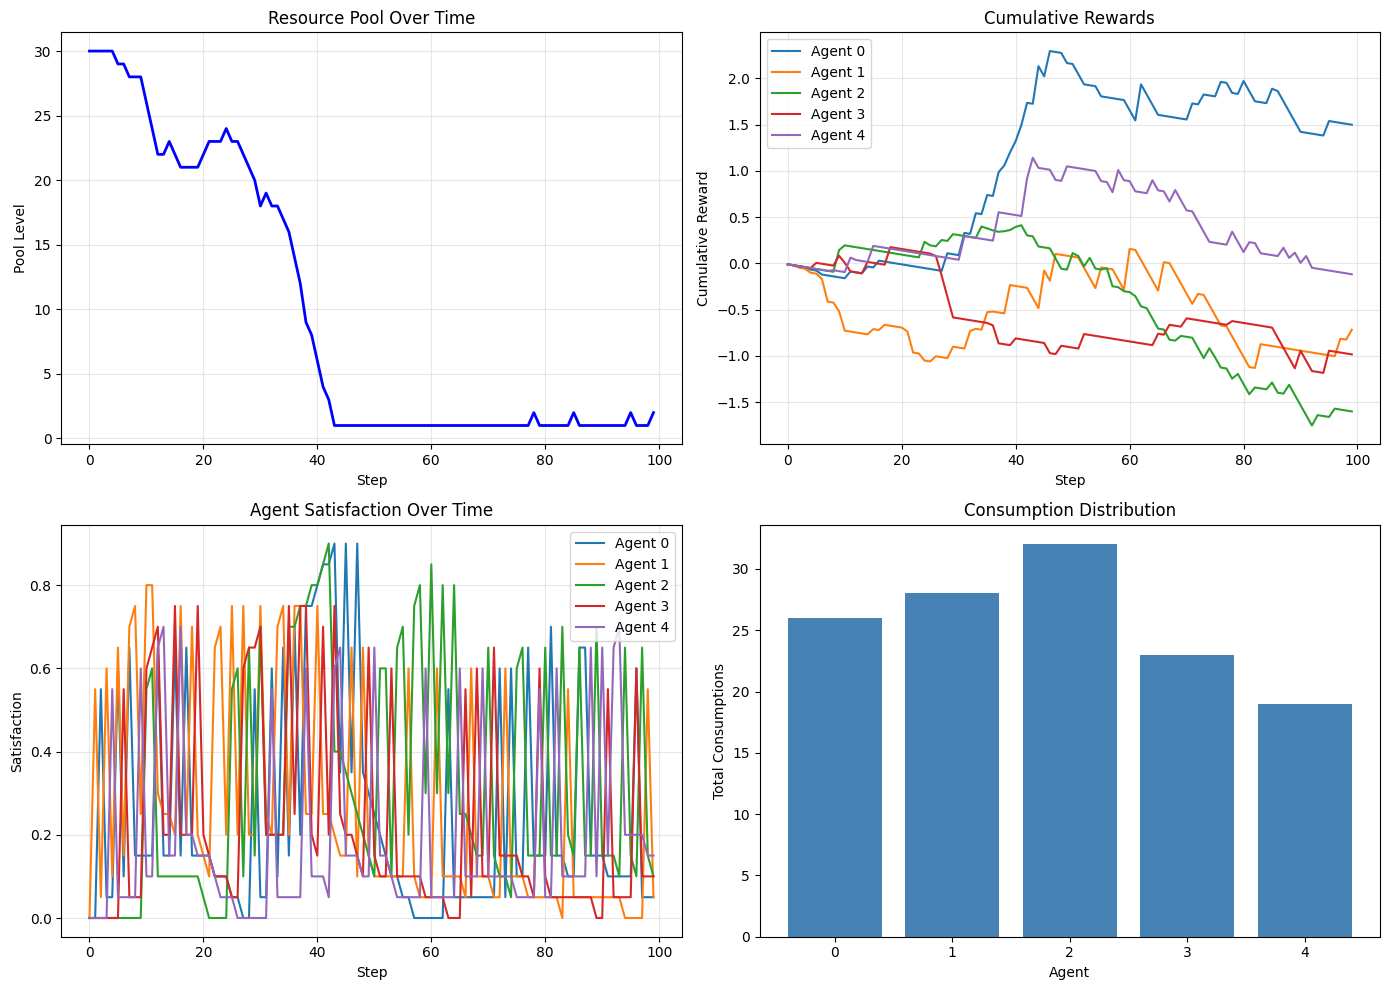

In [10]:
# Visualize episode
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Pool level over time
ax1 = axes[0, 0]
ax1.plot(episode_data['pool_levels'], 'b-', linewidth=2)
ax1.set_xlabel('Step')
ax1.set_ylabel('Pool Level')
ax1.set_title('Resource Pool Over Time')
ax1.grid(True, alpha=0.3)

# Cumulative rewards
ax2 = axes[0, 1]
for i in range(5):
    cumulative = np.cumsum(episode_data['rewards'][i])
    ax2.plot(cumulative, label=f'Agent {i}')
ax2.set_xlabel('Step')
ax2.set_ylabel('Cumulative Reward')
ax2.set_title('Cumulative Rewards')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Satisfaction over time
ax3 = axes[1, 0]
for i in range(5):
    ax3.plot(episode_data['satisfactions'][i], label=f'Agent {i}')
ax3.set_xlabel('Step')
ax3.set_ylabel('Satisfaction')
ax3.set_title('Agent Satisfaction Over Time')
ax3.legend()
ax3.grid(True, alpha=0.3)

# Consumption bar chart
ax4 = axes[1, 1]
bars = ax4.bar(range(5), episode_data['consumptions'], color='steelblue')
ax4.set_xlabel('Agent')
ax4.set_ylabel('Total Consumptions')
ax4.set_title('Consumption Distribution')
ax4.set_xticks(range(5))

plt.tight_layout()
plt.show()

## 4. Compare Empathic vs Non-Empathic Agents

In [11]:
def compute_gini(values):
    """Compute Gini coefficient."""
    values = np.array(values, dtype=float)
    if len(values) == 0 or np.sum(values) == 0:
        return 0.0
    sorted_values = np.sort(values)
    n = len(sorted_values)
    index = np.arange(1, n + 1)
    return (2 * np.sum(index * sorted_values) - (n + 1) * np.sum(sorted_values)) / (n * np.sum(sorted_values))


def run_episode(env, agents, seed=None):
    """Run single episode and return metrics."""
    obs, _ = env.reset(seed=seed)
    for agent, o in zip(agents, obs):
        agent.reset(observation=o)
    
    consumptions = [0] * len(agents)
    total_rewards = [0.0] * len(agents)
    
    for step in range(env.max_steps):
        actions = [agent.select_action(obs[i], training=True) for i, agent in enumerate(agents)]
        next_obs, rewards, terminated, truncated, info = env.step(actions)
        
        for i in range(len(agents)):
            total_rewards[i] += rewards[i]
            if info['consumed'][i]:
                consumptions[i] += 1
        
        for i, agent in enumerate(agents):
            agent.step(next_obs[i], rewards[i], terminated or truncated)
        
        obs = next_obs
        if terminated or truncated:
            break
    
    final_satisfactions = [agent.get_satisfaction() for agent in agents]
    
    return {
        'consumptions': consumptions,
        'total_rewards': total_rewards,
        'final_satisfactions': final_satisfactions,
        'gini_consumption': compute_gini(consumptions),
        'gini_satisfaction': compute_gini(final_satisfactions),
        'total_consumption': sum(consumptions)
    }

In [12]:
# Run comparison experiment
num_episodes = 30
num_agents = 5

results = {'empathic': [], 'non_empathic': []}

for condition, alpha in [('non_empathic', 0.0), ('empathic', 0.5)]:
    print(f"\nRunning {condition} condition (alpha={alpha})...")
    
    # Create environment
    env = EmpathicGraphEnv(
        num_agents=num_agents,
        initial_pool=30,
        regeneration_rate=1.0,
        regeneration_mode='constant',
        graph_type='random',
        edge_probability=0.5,
        empathy_alpha=alpha,
        max_steps=100
    )
    
    # Create agents
    agents = [
        GraphDQNAgent(
            agent_id=i,
            observation_dim=OBSERVATION_DIM,
            epsilon=1.0,
            epsilon_decay=0.99
        )
        for i in range(num_agents)
    ]
    env.set_agents(agents)
    
    # Run episodes
    for ep in range(num_episodes):
        metrics = run_episode(env, agents, seed=42 + ep)
        results[condition].append(metrics)
        
        if (ep + 1) % 10 == 0:
            print(f"  Episode {ep + 1}/{num_episodes}")

print("\nDone!")


Running non_empathic condition (alpha=0.0)...
GraphDQNAgent using device: cpu
  Episode 10/30
  Episode 20/30
  Episode 30/30

Running empathic condition (alpha=0.5)...
GraphDQNAgent using device: cpu
  Episode 10/30
  Episode 20/30
  Episode 30/30

Done!


In [13]:
# Extract metrics
gini_consumption = {
    'empathic': [r['gini_consumption'] for r in results['empathic']],
    'non_empathic': [r['gini_consumption'] for r in results['non_empathic']]
}

gini_satisfaction = {
    'empathic': [r['gini_satisfaction'] for r in results['empathic']],
    'non_empathic': [r['gini_satisfaction'] for r in results['non_empathic']]
}

total_consumption = {
    'empathic': [r['total_consumption'] for r in results['empathic']],
    'non_empathic': [r['total_consumption'] for r in results['non_empathic']]
}

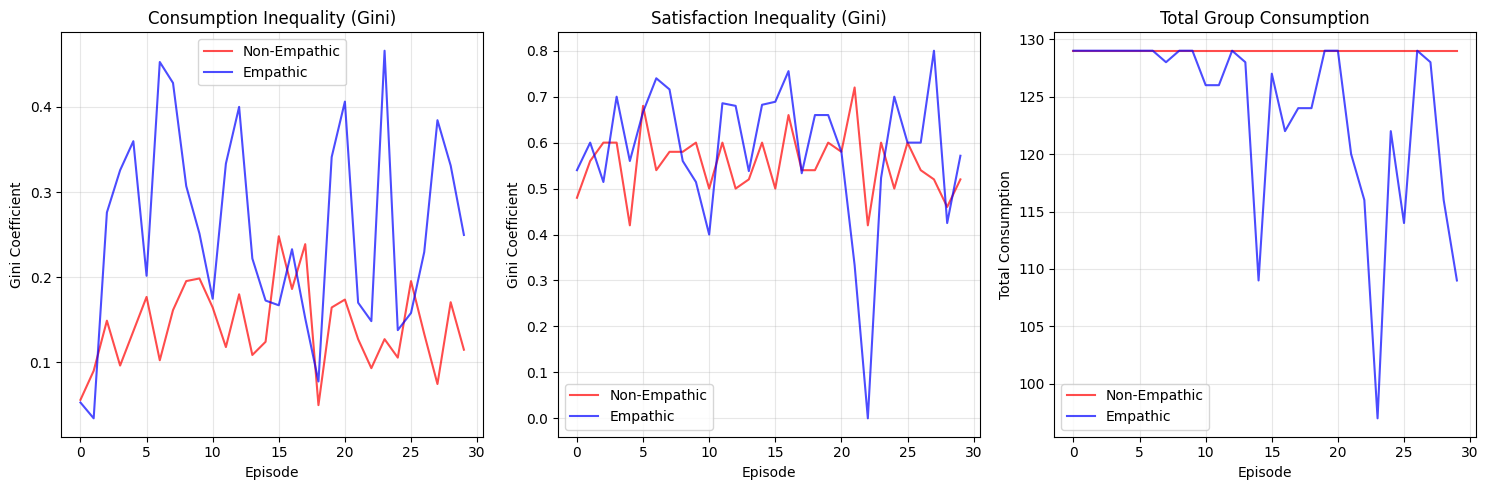

In [14]:
# Visualize comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Gini Consumption
ax1 = axes[0]
ax1.plot(gini_consumption['non_empathic'], 'r-', alpha=0.7, label='Non-Empathic')
ax1.plot(gini_consumption['empathic'], 'b-', alpha=0.7, label='Empathic')
ax1.set_xlabel('Episode')
ax1.set_ylabel('Gini Coefficient')
ax1.set_title('Consumption Inequality (Gini)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Gini Satisfaction
ax2 = axes[1]
ax2.plot(gini_satisfaction['non_empathic'], 'r-', alpha=0.7, label='Non-Empathic')
ax2.plot(gini_satisfaction['empathic'], 'b-', alpha=0.7, label='Empathic')
ax2.set_xlabel('Episode')
ax2.set_ylabel('Gini Coefficient')
ax2.set_title('Satisfaction Inequality (Gini)')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Total Consumption
ax3 = axes[2]
ax3.plot(total_consumption['non_empathic'], 'r-', alpha=0.7, label='Non-Empathic')
ax3.plot(total_consumption['empathic'], 'b-', alpha=0.7, label='Empathic')
ax3.set_xlabel('Episode')
ax3.set_ylabel('Total Consumption')
ax3.set_title('Total Group Consumption')
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
# Summary statistics
print("=" * 60)
print("SUMMARY STATISTICS")
print("=" * 60)

for condition in ['non_empathic', 'empathic']:
    print(f"\n{condition.upper()}:")
    print(f"  Gini Consumption:  mean={np.mean(gini_consumption[condition]):.3f}, std={np.std(gini_consumption[condition]):.3f}")
    print(f"  Gini Satisfaction: mean={np.mean(gini_satisfaction[condition]):.3f}, std={np.std(gini_satisfaction[condition]):.3f}")
    print(f"  Total Consumption: mean={np.mean(total_consumption[condition]):.1f}, std={np.std(total_consumption[condition]):.1f}")

SUMMARY STATISTICS

NON_EMPATHIC:
  Gini Consumption:  mean=0.142, std=0.049
  Gini Satisfaction: mean=0.555, std=0.068
  Total Consumption: mean=129.0, std=0.0

EMPATHIC:
  Gini Consumption:  mean=0.255, std=0.117
  Gini Satisfaction: mean=0.584, std=0.151
  Total Consumption: mean=123.8, std=7.8


## 5. Test Graph Type Effects

In [16]:
# Compare different graph topologies
graph_types = ['fully_connected', 'random', 'small_world', 'ring']
graph_results = {}

for graph_type in graph_types:
    print(f"\nTesting {graph_type} graph...")
    
    env = EmpathicGraphEnv(
        num_agents=5,
        initial_pool=30,
        graph_type=graph_type,
        edge_probability=0.4,
        empathy_alpha=0.5,
        max_steps=100
    )
    
    agents = [GraphDQNAgent(agent_id=i, observation_dim=OBSERVATION_DIM, epsilon=0.5) for i in range(5)]
    env.set_agents(agents)
    
    metrics_list = []
    for ep in range(20):
        metrics = run_episode(env, agents, seed=42 + ep)
        metrics_list.append(metrics)
    
    graph_results[graph_type] = {
        'gini_consumption': [m['gini_consumption'] for m in metrics_list],
        'total_consumption': [m['total_consumption'] for m in metrics_list],
        'density': env.graph.get_density(),
        'avg_degree': env.graph.get_average_degree()
    }

print("\nDone!")


Testing fully_connected graph...
GraphDQNAgent using device: cpu

Testing random graph...
GraphDQNAgent using device: cpu

Testing small_world graph...
GraphDQNAgent using device: cpu

Testing ring graph...
GraphDQNAgent using device: cpu

Done!


C:\Users\evann\AppData\Local\Temp\ipykernel_20200\1986845852.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax1.boxplot(gini_data, labels=graph_types, patch_artist=True)


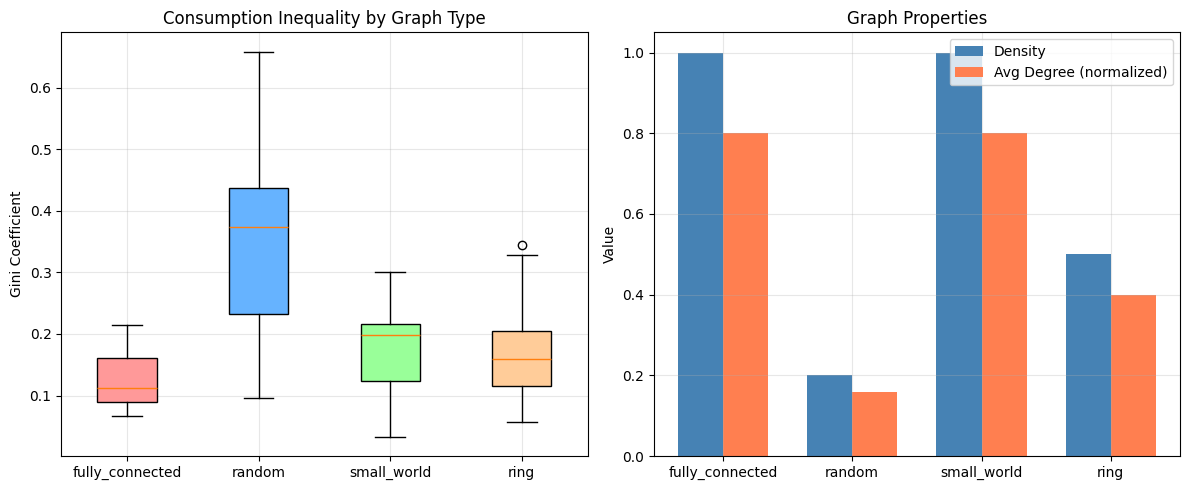

In [17]:
# Visualize graph type comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Box plot of Gini by graph type
ax1 = axes[0]
gini_data = [graph_results[gt]['gini_consumption'] for gt in graph_types]
bp = ax1.boxplot(gini_data, labels=graph_types, patch_artist=True)
colors = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
ax1.set_ylabel('Gini Coefficient')
ax1.set_title('Consumption Inequality by Graph Type')
ax1.grid(True, alpha=0.3)

# Bar chart of graph properties
ax2 = axes[1]
x = np.arange(len(graph_types))
width = 0.35
densities = [graph_results[gt]['density'] for gt in graph_types]
degrees = [graph_results[gt]['avg_degree'] / 5 for gt in graph_types]  # Normalize

ax2.bar(x - width/2, densities, width, label='Density', color='steelblue')
ax2.bar(x + width/2, degrees, width, label='Avg Degree (normalized)', color='coral')
ax2.set_xticks(x)
ax2.set_xticklabels(graph_types)
ax2.set_ylabel('Value')
ax2.set_title('Graph Properties')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Observation Space Validation

In [18]:
# Examine observation structure
env = EmpathicGraphEnv(
    num_agents=4,
    max_neighbors=4,
    graph_type='fully_connected',
    empathy_alpha=0.5
)

agents = [GraphDQNAgent(agent_id=i, observation_dim=3 + 4*2) for i in range(4)]
env.set_agents(agents)

obs, _ = env.reset(seed=42)

print("Observation Structure (per agent):")
print("  [0]: Own satisfaction")
print("  [1]: Own emotion")
print("  [2]: Pool level (normalized)")
print("  [3,4]: Neighbor 0 (emotion, weight)")
print("  [5,6]: Neighbor 1 (emotion, weight)")
print("  ...")

print(f"\nObservation shape: {obs[0].shape}")
print(f"\nSample observation for Agent 0:")
print(f"  Own satisfaction: {obs[0][0]:.3f}")
print(f"  Own emotion:      {obs[0][1]:.3f}")
print(f"  Pool level:       {obs[0][2]:.3f}")
print(f"  Full vector: {obs[0]}")

GraphDQNAgent using device: cpu
Observation Structure (per agent):
  [0]: Own satisfaction
  [1]: Own emotion
  [2]: Pool level (normalized)
  [3,4]: Neighbor 0 (emotion, weight)
  [5,6]: Neighbor 1 (emotion, weight)
  ...

Observation shape: (11,)

Sample observation for Agent 0:
  Own satisfaction: 0.000
  Own emotion:      -1.000
  Pool level:       0.500
  Full vector: [ 0.  -1.   0.5 -1.   1.  -1.   1.  -1.   1.   0.   0. ]


## 7. Affiliation Theory Hooks (Preview)

In [19]:
# Demonstrate weight update mechanism (for future affiliation theory)
graph = SocialGraph(num_agents=4, graph_type='fully_connected', seed=42)

print("Initial weights:")
print(graph.weights)

# Simulate cooperative interactions between agents 0 and 1
for _ in range(5):
    graph.update_weight(0, 1, 'cooperative')

# Simulate competitive interactions between agents 2 and 3
for _ in range(5):
    graph.update_weight(2, 3, 'competitive')

print("\nWeights after interactions:")
print(graph.weights)

print(f"\nWeight 0->1: {graph.get_edge_weight(0, 1):.3f} (strengthened)")
print(f"Weight 2->3: {graph.get_edge_weight(2, 3):.3f} (weakened)")

Initial weights:
[[0. 1. 1. 1.]
 [1. 0. 1. 1.]
 [1. 1. 0. 1.]
 [1. 1. 1. 0.]]

Weights after interactions:
[[0.1       1.6105101 1.        1.       ]
 [1.6105101 0.1       1.        1.       ]
 [1.        1.        0.1       0.7737809]
 [1.        1.        0.7737809 0.1      ]]

Weight 0->1: 1.611 (strengthened)
Weight 2->3: 0.774 (weakened)


## Summary

This notebook validated:
1. **SocialGraph**: Different topologies work correctly
2. **ResourcePool**: Consumption and regeneration work as expected
3. **EmpathicGraphEnv**: Environment runs properly with agents
4. **Empathic vs Non-Empathic**: Framework ready for comparison experiments
5. **Graph Type Effects**: Different topologies affect behavior
6. **Observation Space**: Correctly structured for DQN input
7. **Affiliation Hooks**: Weight update mechanism ready for future use

### Next Steps
- Run full training with `main_graph.py`
- Analyze results with extended episodes
- Implement affiliation theory (weighted connections)